# Assignment: Ensemble Learning Techniques Using Python

**Course:** AI / ML Domain 3 · B.Tech 3rd Year  
**Name:** Ajay Chauhan  
**Roll Number:** 2400320100110  
**Branch:** Computer Science and Engineering (CSE)  
**Section:** 13

**Objective:** To study and implement ensemble learning methods and compare their classification performance on the Breast Cancer Wisconsin (Diagnostic) dataset. The target is to classify each observation as **Benign (B)** or **Malignant (M)**.

**Evaluation protocol:** The assignment uses an 80:20 stratified train-test split with `random_state=42`. Model selection and tuning are performed using five-fold cross-validation on the training set only. The test set is reserved for final evaluation.

## Setup: libraries, reproducibility and cross-validation

The following setup imports the required Python libraries, fixes the random seed at **42** as specified in the assignment, and creates one stratified five-fold splitter. Reusing the same folds makes model comparisons fair.

In [1]:

import os, time, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, log_loss)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# ONE splitter object used for every cross-validation -> every model is scored on identical folds
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

def say(text, width=115):
    """Print a wrapped sentence (used for the data-driven observations)."""
    print(textwrap.fill(text, width))

## Q1. Introduction to ensemble learning

**Ensemble learning** means training several models (the *base learners*) on the same problem and merging their outputs, by voting, averaging or with a second-level model, into a single prediction.

**Why a group can beat one model**

1. **Lower variance.** A flexible model such as an unpruned decision tree changes a lot when the training sample changes a little. If we average *M* such models whose predictions have variance σ² and mean pairwise correlation ρ, the variance of the average is  ρσ² + (1 − ρ)σ²/M. It shrinks as *M* grows and shrinks further when the models are less correlated, which is the principle behind bagging and Random Forest.
2. **Lower bias.** A single weak learner (e.g. a one-split tree) is too simple. Boosting adds weak learners one after another, each aimed at what the ensemble still gets wrong, so the sum can represent a far more complex boundary than any one member.
3. **Diversity of errors.** If the members are individually better than chance and make *different* mistakes, the majority is right more often than any member. (For independent members, the probability that the majority is correct tends to 1 as the number of members grows.)
4. **Hedging the model choice.** With a finite sample, many different models fit the data about equally well; averaging them avoids betting everything on one of them.

**Limits.** If all members make the same mistakes, nothing is gained. Ensembles also cost more training/prediction time and are harder to interpret.

## Q2. Bagging vs boosting vs stacking

| Aspect | Bagging | Boosting | Stacking |
|---|---|---|---|
| Main aim | Cut **variance** | Cut **bias** (and some variance) | Combine **different kinds** of models |
| Training procedure | Learners trained **independently / in parallel**, each on its own bootstrap sample | Learners trained **one after another**; every new learner concentrates on the errors of the current ensemble (re-weighted rows or residuals) | Several heterogeneous base learners are trained; a **meta-learner** is then trained on their out-of-fold predictions |
| Typical base learner | Strong, high-variance (deep trees) | Weak, high-bias (stumps / shallow trees) | Anything (tree, KNN, SVM, ...) |
| How predictions are combined | Majority vote / plain average, equal weights | Weighted vote or additive sum (weights from learner accuracy or the learning rate) | The meta-learner **learns** the weights |
| Noise sensitivity | Robust | Can chase noisy labels | Depends on the members |
| Example algorithms | `BaggingClassifier`, Random Forest, Extra-Trees | AdaBoost, Gradient Boosting, XGBoost, LightGBM | `StackingClassifier` |

*Voting* is the simple relative of stacking: different models are merged with a **fixed** rule (majority or mean probability) instead of a learned one.

## Q3. Dataset exploration

The loader below tries, in order: (1) a local `data.csv` (the Kaggle file), (2) a download through `kagglehub`, (3) the **same UCI WDBC data that ships with scikit-learn**, renamed to the Kaggle layout (`id`, `diagnosis`, `*_mean / *_se / *_worst`, empty `Unnamed: 32`). So the notebook runs even without internet, and the later cells do not change.

In [2]:
def load_wdbc():
    # 1) local copy of the Kaggle file
    import glob
    candidates = ["data.csv", "/content/data.csv", "data/data.csv", "breast-cancer.csv"]
    candidates += glob.glob("/kaggle/input/*/data.csv") + glob.glob("/kaggle/input/*/*.csv")   # Kaggle notebooks
    for p in candidates:
        if os.path.exists(p):
            d0 = pd.read_csv(p)
            if "diagnosis" in d0.columns:                      # make sure it is the right file
                return d0, f"Kaggle CSV ({p})"
    # 2) kagglehub download
    try:
        import kagglehub
        folder = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
        return pd.read_csv(os.path.join(folder, "data.csv")), "Kaggle (kagglehub)"
    except Exception:
        pass
    # 3) identical UCI data bundled with scikit-learn, renamed to Kaggle's column layout
    from sklearn.datasets import load_breast_cancer
    b = load_breast_cancer()
    names = []
    for nm in b.feature_names:
        if nm.startswith("mean "):    base, suf = nm[5:], "_mean"
        elif nm.startswith("worst "): base, suf = nm[6:], "_worst"
        else:                         base, suf = nm[:-6], "_se"          # "... error"
        names.append(base.replace("fractal dimension", "fractal_dimension") + suf)
    d = pd.DataFrame(b.data, columns=names)
    d.insert(0, "diagnosis", np.where(b.target == 0, "M", "B"))             # sklearn: 0 = malignant
    d.insert(0, "id", np.arange(1, len(d) + 1))                            # placeholder ids
    d["Unnamed: 32"] = np.nan                                              # Kaggle's empty last column
    return d, "scikit-learn copy of UCI WDBC (offline fallback)"

df, DATA_SOURCE = load_wdbc()
print("Data source :", DATA_SOURCE)
print("Dimensions  :", df.shape, "(rows, columns)")
print("\nFirst five records:")
display(df.head())
print("\nColumn names:")
print(list(df.columns))
print("\nData types (count):")
print(df.dtypes.astype(str).value_counts())
print("\nFirst columns in detail:")
print(df.dtypes.head(4))

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Data source : Kaggle (kagglehub)
Dimensions  : (569, 33) (rows, columns)

First five records:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Data types (count):
float64    31
int64       1
object      1
Name: count, dtype: int64

First columns in detail:
id                int64
diagnosis        object
radius_mean     float64
texture_mean    float64
dtype: object


**Target variable:** `diagnosis` — `M` = malignant, `B` = benign.  
**Input features:** the 30 numeric columns. They describe the cell nuclei seen in a digitised image of a fine-needle aspirate: ten measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each stored three ways — the **mean**, the **standard error (se)** and the **worst** value (mean of the three largest).  
**Not features:** `id` (just a record label) and `Unnamed: 32` (an empty column created by a trailing comma in the CSV).

## Q4. Data preparation

In [3]:
miss = df.isnull().sum()
print("Columns with missing values:")
print(miss[miss > 0] if (miss > 0).any() else "none")

print("\nDuplicate rows              :", df.duplicated().sum())
print("Duplicate patient ids       :", df["id"].duplicated().sum())

empty_cols = df.columns[df.isnull().all()].tolist()
print("Completely empty columns    :", empty_cols)

data = df.drop(columns=["id"] + empty_cols)          # remove identifier + empty column(s)
print("\nDuplicate rows after drop   :", data.duplicated().sum())
print("Shape after cleaning        :", data.shape)
print("Missing values left         :", int(data.isnull().sum().sum()))

Columns with missing values:
Unnamed: 32    569
dtype: int64

Duplicate rows              : 0
Duplicate patient ids       : 0
Completely empty columns    : ['Unnamed: 32']

Duplicate rows after drop   : 0
Shape after cleaning        : (569, 31)
Missing values left         : 0


**Preprocessing decisions**

* **Empty column removed.** `Unnamed: 32` is 100 % missing, so it carries no information; imputing it would be meaningless.
* **No imputation.** All 30 real features are complete, so there is nothing to fill in (imputation would only add assumptions).
* **Duplicates.** None found, so no row is removed and no patient is counted twice.
* **`id` removed.** It is an arbitrary label with no medical meaning; a flexible model could memorise it.
* **Outliers kept.** Very large tumour measurements are real and clinically relevant (large, irregular nuclei suggest malignancy); deleting them would remove signal.
* **Scaling postponed** to Q6, because it must be *fitted on training data only*.

## Q5. Exploratory data analysis

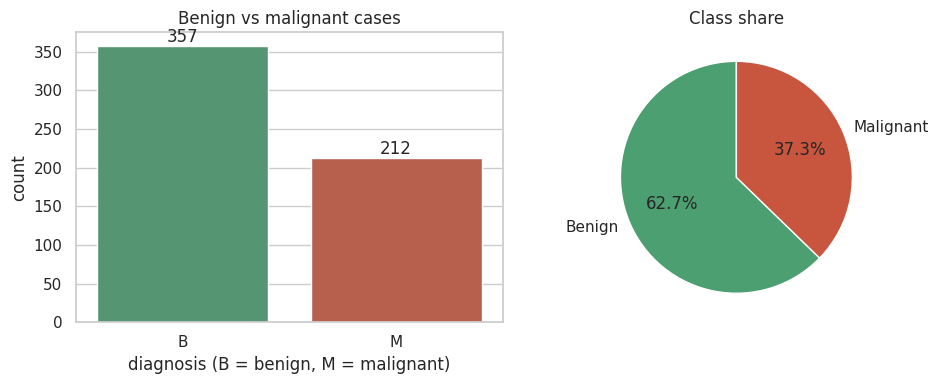

{'B': 357, 'M': 212} -> {'B': 0.627, 'M': 0.373}


In [4]:
pal = {"B": "#4C9F70", "M": "#C8553D"}
counts = data["diagnosis"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=data, x="diagnosis", order=["B", "M"], hue="diagnosis", palette=pal, legend=False, ax=ax[0])
ax[0].set_title("Benign vs malignant cases"); ax[0].set_xlabel("diagnosis (B = benign, M = malignant)")
for bar in ax[0].patches:
    ax[0].annotate(int(bar.get_height()), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                   ha="center", va="bottom")
ax[1].pie(counts[["B", "M"]], labels=["Benign", "Malignant"], autopct="%1.1f%%",
          colors=[pal["B"], pal["M"]], startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); savefig("q5_class_distribution"); plt.show()
print(counts.to_dict(), "->", (counts / len(data)).round(3).to_dict())

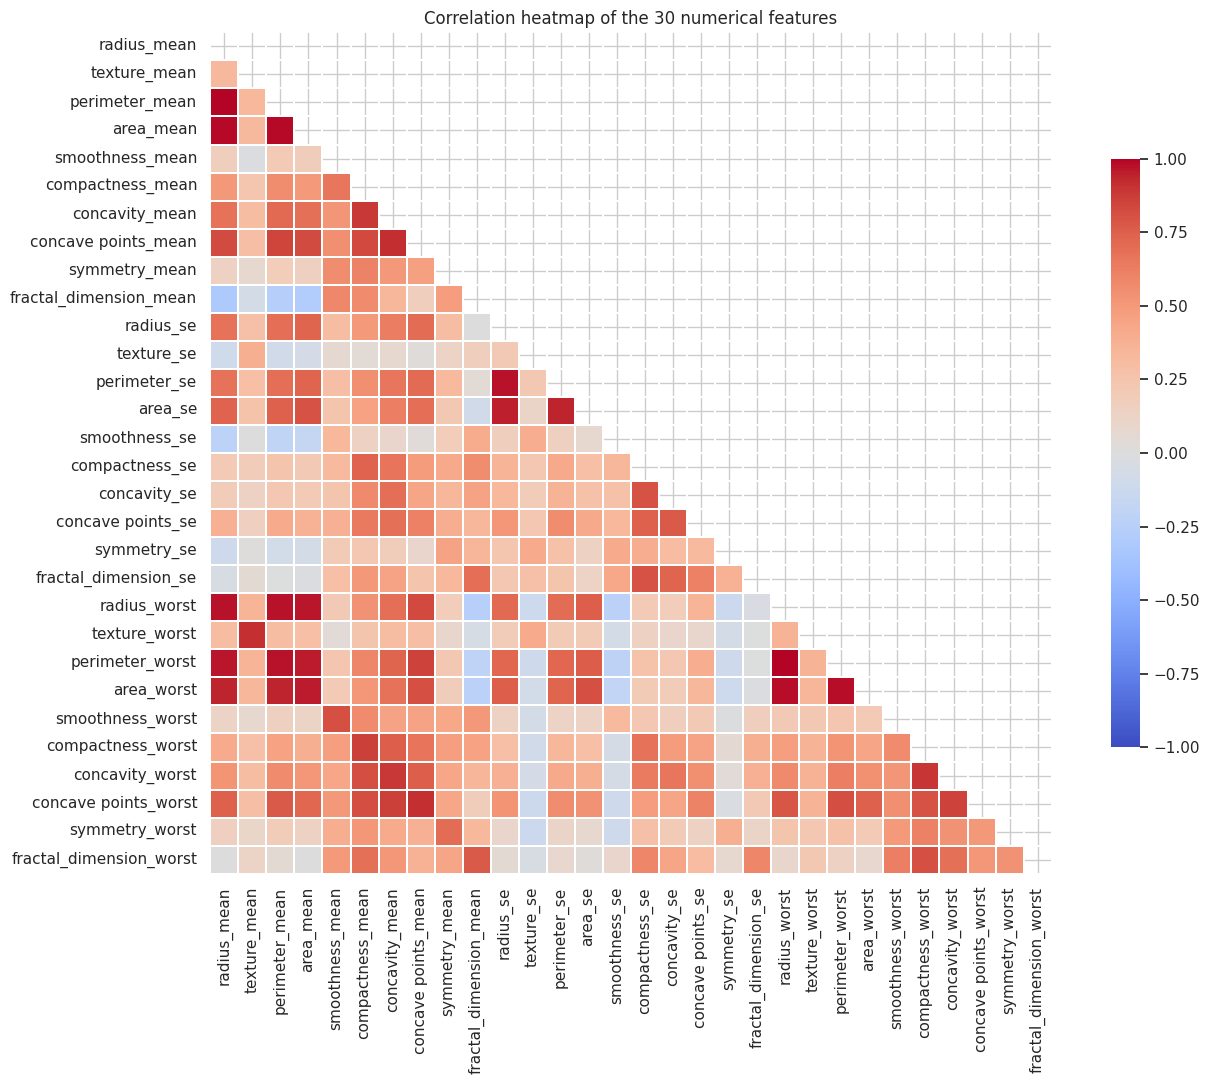

Strongest feature pairs:
 radius_mean     perimeter_mean     0.998
radius_worst    perimeter_worst    0.994
radius_mean     area_mean          0.987
perimeter_mean  area_mean          0.987
radius_worst    area_worst         0.984
dtype: float64

Pairs with |r| > 0.90: 21 of 435

Most related to malignancy (correlation with M=1):
 concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
dtype: float64

Least related:
 fractal_dimension_mean   -0.013
texture_se               -0.008
symmetry_se              -0.007
dtype: float64


In [5]:
feat_df = data.drop(columns="diagnosis")
corr = feat_df.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation heatmap of the 30 numerical features")
plt.tight_layout(); savefig("q5_correlation_heatmap"); plt.show()

# numbers that back the three observations
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
top_pairs = upper.reindex(upper.abs().sort_values(ascending=False).index)
print("Strongest feature pairs:\n", top_pairs.head(5).round(3))
print(f"\nPairs with |r| > 0.90: {(upper.abs() > 0.90).sum()} of {len(upper)}")
target_corr = feat_df.corrwith(data["diagnosis"].map({"M": 1, "B": 0}))
order = target_corr.abs().sort_values(ascending=False).index
print("\nMost related to malignancy (correlation with M=1):\n", target_corr[order].head(5).round(3))
print("\nLeast related:\n", target_corr[order].tail(3).round(3))

**Three observations** (the numbers are printed by the cells above)

1. **The classes are moderately imbalanced** — roughly 63 % benign and 37 % malignant. A model that always says "benign" would already be ≈ 63 % accurate, so accuracy alone is not enough; precision/recall/F1 for the malignant class matter, and the split must be stratified.
2. **Size features are almost duplicates of each other.** Radius, perimeter and area are extremely correlated (r ≈ 0.99 for the *mean* versions, and similarly for the *worst* versions), and many other pairs exceed |r| = 0.9. So the 30 columns hold much fewer than 30 independent pieces of information. Tree ensembles tolerate this, but it spreads feature-importance across the duplicates (see Q20).
3. **"Worst" size and concavity measurements are most related to malignancy.** `concave points_worst`, `perimeter_worst`, `concave points_mean` and `radius_worst` have the highest correlation with the malignant label (about 0.75–0.80): malignant nuclei are larger and have a more irregular, indented outline. Features such as `symmetry_se`, `texture_se` or `fractal_dimension_mean` are almost unrelated to the diagnosis.

## Q6. Encoding, stratified 80 : 20 split and scaling

In [6]:
X = data.drop(columns="diagnosis")
y = data["diagnosis"].map({"M": 1, "B": 0})        # malignant = 1 (positive class), benign = 0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of malignant -> whole: %.3f | train: %.3f | test: %.3f" % (y.mean(), y_train.mean(), y_test.mean()))

# Scaling is fitted on the TRAINING data only
scaler = StandardScaler().fit(X_train)
print("\nMean of first 3 scaled features, train:", scaler.transform(X_train).mean(axis=0)[:3].round(3))
print("Mean of first 3 scaled features, test :", scaler.transform(X_test).mean(axis=0)[:3].round(3),
      "(not exactly 0 - the test data did not take part in fitting)")

def with_scaler(estimator):
    """Pipeline(StandardScaler -> estimator). Inside cross-validation the scaler is re-fitted on every
    training fold only, so nothing from the validation fold leaks into the scaling."""
    return make_pipeline(StandardScaler(), estimator)

Train: (455, 30) | Test: (114, 30)
Share of malignant -> whole: 0.373 | train: 0.374 | test: 0.368

Mean of first 3 scaled features, train: [-0.  0.  0.]
Mean of first 3 scaled features, test : [-0.054 -0.149 -0.05 ] (not exactly 0 - the test data did not take part in fitting)


**Stratification** keeps the benign : malignant ratio (≈ 63 : 37) the same in the training set, the test set and — when `StratifiedKFold` is used — in every cross-validation fold. With only 569 rows, a purely random split could give a test set with an unusual share of malignant cases and therefore unreliable metrics.

**Where scaling is needed.** Logistic Regression, KNN and SVC depend on feature magnitudes (distances / margins / regularisation), so they are wrapped in `with_scaler(...)`. Tree-based models (Decision Tree, Bagging, Random Forest, AdaBoost, Gradient Boosting, XGBoost, LightGBM) split on thresholds and are unaffected by monotone rescaling, so they get no scaler. Because the scaler lives inside a **pipeline**, it is fitted only on the training part of each fold — no leakage.

In [7]:
# Small helper: 5-fold stratified CV accuracy on the TRAINING set, with a log of every experiment
cv_log = []
def cv_eval(label, model, show=True):
    t0 = time.perf_counter()
    scores = cross_val_score(model, X_train, y_train, cv=CV, scoring="accuracy")
    sec = time.perf_counter() - t0
    cv_log.append({"Model": label, "CV mean accuracy": scores.mean(), "CV std": scores.std(), "CV time (s)": sec})
    if show:
        print(f"{label:<32} CV accuracy = {scores.mean():.4f} +/- {scores.std():.4f}   ({sec:.2f}s)")
    return scores

## Q7. Baseline classifier: Decision Tree

In [8]:
tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
tree_train_acc = accuracy_score(y_train, tree.predict(X_train))
tree_cv = cv_eval("Decision Tree (baseline)", DecisionTreeClassifier(random_state=SEED))

print(f"\nTraining accuracy          : {tree_train_acc:.4f}")
print(f"5-fold CV accuracy (train) : {tree_cv.mean():.4f}  (folds: {tree_cv.round(3)})")
print(f"Tree depth / leaves        : {tree.get_depth()} / {tree.get_n_leaves()}")
gap = tree_train_acc - tree_cv.mean()
print(f"Train - CV accuracy gap: {gap*100:.1f} percentage points")

Decision Tree (baseline)         CV accuracy = 0.9231 +/- 0.0326   (0.09s)

Training accuracy          : 1.0000
5-fold CV accuracy (train) : 0.9231  (folds: [0.89  0.967 0.89  0.912 0.956])
Tree depth / leaves        : 8 / 24
Train - CV accuracy gap: 7.7 percentage points


**Why do we need a baseline?** A baseline is the simplest sensible model. It gives the reference against which every ensemble is judged: without it, a number such as "96 % accuracy" has no meaning, and we could not tell whether the extra training time, memory and loss of interpretability of an ensemble actually buy anything. A fully grown decision tree is a good baseline for this assignment because it is a high-variance model, exactly the weakness that bagging and boosting are designed to fix.

## Q8. Bootstrap sampling

A **bootstrap sample** is obtained by drawing *n* rows **with replacement** from a training set of *n* rows. Every draw picks each row with probability 1/*n*, so some rows are chosen several times (**repeated**) and others never (**omitted**, also called *out-of-bag*). A particular row is missed by all *n* draws with probability (1 − 1/*n*)ⁿ → e⁻¹ ≈ 0.368, so a bootstrap sample contains about **63.2 %** distinct rows and leaves out about **36.8 %**. Different samples give different trees — this is where the diversity in bagging comes from.

Original rows   : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Bootstrap sample: [0, 2, 3, 5, 6, 6, 7, 8, 8, 9]
Repeated rows   : {6: 2, 8: 2}
Omitted rows    : [1, 4]

Training rows n = 455; theoretical share of distinct rows = 0.633



,Sample,Distinct rows,Omitted (out-of-bag),Rows drawn 2+ times,Most repeats of one row,% distinct
0,1,285,170,126,5,62.6
1,2,285,170,129,5,62.6
2,3,305,150,121,4,67.0


Sample 1 - examples of repeated rows (position -> times drawn): {10: 3, 36: 3, 41: 3, 59: 3, 63: 4}
Sample 1 - examples of omitted rows (positions): [0, 1, 5, 7, 12, 13, 21, 22]


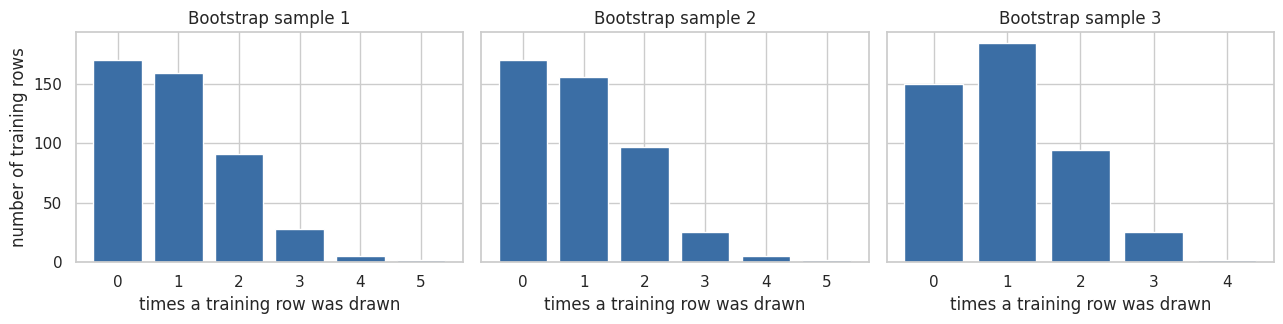

In [9]:
# (a) tiny illustration with 10 row numbers
small_rng = np.random.default_rng(7)
ids = np.arange(10)
pick = small_rng.choice(ids, size=10, replace=True)
print("Original rows   :", ids.tolist())
print("Bootstrap sample:", sorted(pick.tolist()))
print("Repeated rows   :", {int(r): int(c) for r, c in zip(*np.unique(pick, return_counts=True)) if c > 1})
print("Omitted rows    :", sorted(int(i) for i in set(ids) - set(pick)))

# (b) three bootstrap samples of the real training set
n = len(X_train)
rng = np.random.default_rng(SEED)
print(f"\nTraining rows n = {n}; theoretical share of distinct rows = {1 - (1 - 1/n)**n:.3f}\n")

draw_counts, rows = [], []
for s in (1, 2, 3):
    chosen = rng.integers(0, n, size=n)               # row positions drawn WITH replacement
    times = np.bincount(chosen, minlength=n)          # how often each training row was drawn
    draw_counts.append(times)
    rows.append({"Sample": s,
                 "Distinct rows": int((times > 0).sum()),
                 "Omitted (out-of-bag)": int((times == 0).sum()),
                 "Rows drawn 2+ times": int((times > 1).sum()),
                 "Most repeats of one row": int(times.max()),
                 "% distinct": round(100 * (times > 0).mean(), 1)})
display(pd.DataFrame(rows))

t1 = draw_counts[0]
print("Sample 1 - examples of repeated rows (position -> times drawn):",
      {int(i): int(t1[i]) for i in np.where(t1 >= 3)[0][:5]})
print("Sample 1 - examples of omitted rows (positions):", np.where(t1 == 0)[0][:8].tolist())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for k, (ax, t) in enumerate(zip(axes, draw_counts), 1):
    v, f = np.unique(t, return_counts=True)
    ax.bar(v, f, color="#3B6EA5"); ax.set_xticks(v)
    ax.set_title(f"Bootstrap sample {k}"); ax.set_xlabel("times a training row was drawn")
axes[0].set_ylabel("number of training rows")
plt.tight_layout(); savefig("q8_bootstrap"); plt.show()

**Reading the output.** In each of the three samples only about 63 % of the training rows appear at all (the *distinct* column); the remaining ≈ 37 % are **omitted**, and roughly a quarter of the rows are **repeated** two or more times (a bar at 0 in the histograms = omitted rows, at 1 = drawn once, at 2 or more = repeated). Every tree of a bagging ensemble sees a different such sample, and the omitted rows can even be used as a free validation set (the *out-of-bag* estimate).

## Q9. Bagging classifier

In [10]:
bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED),
                        n_estimators=100, random_state=SEED, n_jobs=1)
bag_cv = cv_eval("Bagging (100 trees)", bag)

print("\nFold scores  Decision Tree:", tree_cv.round(3))
print("Fold scores  Bagging      :", bag_cv.round(3))
print(f"Bagging vs Decision Tree: {(bag_cv.mean()-tree_cv.mean())*100:+.2f} points | folds won: {(bag_cv > tree_cv).sum()} of 5 | std {tree_cv.std():.4f} -> {bag_cv.std():.4f}")

Bagging (100 trees)              CV accuracy = 0.9626 +/- 0.0226   (4.17s)

Fold scores  Decision Tree: [0.89  0.967 0.89  0.912 0.956]
Fold scores  Bagging      : [0.967 1.    0.945 0.934 0.967]
Bagging vs Decision Tree: +3.96 points | folds won: 5 of 5 | std 0.0326 -> 0.0226


**Comparison.** Averaging many trees, each trained on a different bootstrap sample, removes a large part of the variance that made the single tree unstable: every tree still overfits its own sample, but their individual mistakes are different and partly cancel in the vote. The printed numbers above give the exact improvement over the baseline and the per-fold comparison.

## Q10. Effect of the number of estimators in bagging

,n_estimators,mean CV accuracy,std,CV time (s)
0,10,0.9604,0.0192,0.4583
1,50,0.9604,0.0192,2.5813
2,100,0.9626,0.0226,4.8923
3,200,0.9582,0.0245,8.7862


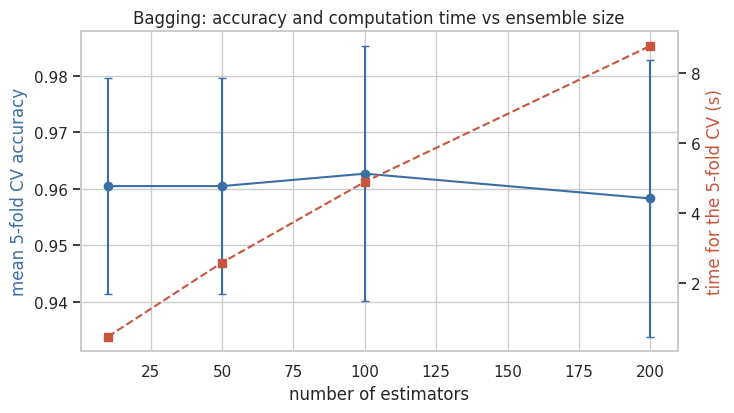

Accuracy spread over 10-200 trees: 0.44 points | CV time 0.46s -> 8.79s | selected: 100 trees


In [11]:
sizes = [10, 50, 100, 200]
rows = []
for m in sizes:
    model = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED),
                              n_estimators=m, random_state=SEED, n_jobs=1)
    t0 = time.perf_counter()
    sc = cross_val_score(model, X_train, y_train, cv=CV, scoring="accuracy")
    rows.append({"n_estimators": m, "mean CV accuracy": sc.mean(), "std": sc.std(),
                 "CV time (s)": time.perf_counter() - t0})
bag_size_tbl = pd.DataFrame(rows)
display(bag_size_tbl.round(4))

fig, ax1 = plt.subplots(figsize=(7.5, 4.3))
ax1.errorbar(bag_size_tbl["n_estimators"], bag_size_tbl["mean CV accuracy"], yerr=bag_size_tbl["std"],
             marker="o", capsize=3, color="#3B6EA5")
ax1.set_xlabel("number of estimators"); ax1.set_ylabel("mean 5-fold CV accuracy", color="#3B6EA5")
ax2 = ax1.twinx()
ax2.plot(bag_size_tbl["n_estimators"], bag_size_tbl["CV time (s)"], marker="s", ls="--", color="#C8553D")
ax2.set_ylabel("time for the 5-fold CV (s)", color="#C8553D"); ax2.grid(False)
plt.title("Bagging: accuracy and computation time vs ensemble size")
plt.tight_layout(); savefig("q10_bagging_estimators"); plt.show()

# selection rule (training data only): highest CV accuracy, fewer trees if tied
best_bag_n = int(bag_size_tbl.sort_values(["mean CV accuracy", "n_estimators"], ascending=[False, True]).iloc[0]["n_estimators"])
spread = bag_size_tbl["mean CV accuracy"].max() - bag_size_tbl["mean CV accuracy"].min()
print(f"Accuracy spread over 10-200 trees: {spread*100:.2f} points | CV time {bag_size_tbl['CV time (s)'].iloc[0]:.2f}s -> {bag_size_tbl['CV time (s)'].iloc[-1]:.2f}s | selected: {best_bag_n} trees")

**Discussion.** Compare the measured mean cross-validation accuracy and runtime in the table above. In general, adding estimators can make bagging more stable, but the improvement may become small after enough trees have been included. Training time usually increases as the ensemble grows. The best size is selected using training-set cross-validation only; the untouched test set is not used for this decision.

## Q11. Random Forest

A Random Forest is **bagging of decision trees plus random feature selection at every split**.

| | Ordinary bagging of trees | Random Forest |
|---|---|---|
| Rows | bootstrap sample per tree | bootstrap sample per tree |
| Features considered at a split | **all** *p* features | a **random subset** of *m* features (default m = √p, i.e. 5 of our 30), drawn again at **every node** |
| Consequence | a few very strong features (here the "worst" size / concave-points variables) win the top splits in almost every tree, so the trees are alike (high correlation ρ) | the strong features are often not in the subset, so trees are forced to differ; lower ρ means a larger variance reduction when averaging |
| Cost per split | all *p* features evaluated | only *m* features evaluated (faster) |

The subset is drawn per *split*, not once per tree. With `max_features=None` a Random Forest becomes ordinary bagging.

In [12]:
rf = RandomForestClassifier(n_estimators=100, max_features="sqrt", random_state=SEED, n_jobs=1)
rf_cv = cv_eval("Random Forest (default)", rf)

# same forest but every split may look at all features  ->  equivalent to bagging of trees
rf_all = RandomForestClassifier(n_estimators=100, max_features=None, random_state=SEED, n_jobs=1)
rf_all_cv = cv_eval("RF with max_features=None", rf_all)

print(f"Random Forest {rf_cv.mean():.4f} | max_features=None {rf_all_cv.mean():.4f} | plain bagging {bag_cv.mean():.4f}")

Random Forest (default)          CV accuracy = 0.9648 +/- 0.0146   (1.86s)
RF with max_features=None        CV accuracy = 0.9495 +/- 0.0215   (3.71s)
Random Forest 0.9648 | max_features=None 0.9495 | plain bagging 0.9626


## Q12. Random Forest tuning (RandomizedSearchCV, training data only)

In [13]:
rf_space = {"n_estimators": [100, 200],
            "max_depth": [None, 6],
            "max_features": ["sqrt", 0.5]}
n_combos = int(np.prod([len(v) for v in rf_space.values()]))
print("Search space:", rf_space)
print(f"{n_combos} possible combinations; RandomizedSearchCV checks all {n_combos} combinations x 5 folds")

t0 = time.perf_counter()
rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=1),
                               rf_space, n_iter=n_combos, cv=CV, scoring="accuracy",
                               random_state=SEED, n_jobs=1)
rf_search.fit(X_train, y_train)
print(f"Search time: {time.perf_counter() - t0:.1f}s")
print("Best parameters:", rf_search.best_params_)
print(f"Best CV score: {rf_search.best_score_:.4f} (default forest in Q11: {rf_cv.mean():.4f})")

res = pd.DataFrame(rf_search.cv_results_)
display(res[["param_n_estimators", "param_max_depth", "param_max_features",
             "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").round(4))
print(f"CV accuracy range: {res['mean_test_score'].min():.4f} - {res['mean_test_score'].max():.4f}")
best_rf_params = rf_search.best_params_

Search space: {'n_estimators': [100, 200], 'max_depth': [None, 6], 'max_features': ['sqrt', 0.5]}
8 possible combinations; RandomizedSearchCV checks all 8 combinations x 5 folds
Search time: 29.8s
Best parameters: {'n_estimators': 100, 'max_features': 0.5, 'max_depth': None}
Best CV score: 0.9714 (default forest in Q11: 0.9648)


,param_n_estimators,param_max_depth,param_max_features,mean_test_score,std_test_score,rank_test_score
2,100,None,0.5,0.9714,0.0179,1
6,100,6,0.5,0.9714,0.0179,1
3,200,None,0.5,0.9692,0.0189,3
4,100,6,sqrt,0.9670,0.0155,4
7,200,6,0.5,0.9670,0.0197,4
0,100,None,sqrt,0.9648,0.0146,6
5,200,6,sqrt,0.9648,0.0201,7
1,200,None,sqrt,0.9626,0.0149,8


CV accuracy range: 0.9626 - 0.9714


**Report.** The Random Forest search tests the listed values of `n_estimators`, `max_depth` and `max_features` with five-fold stratified cross-validation on the training set. The best parameters and score are printed above and are used in later sections. The compact search space keeps the experiment practical while covering all three parameters required by the question.

## Q13. AdaBoost

**How AdaBoost concentrates on mistakes.** Every training row has a weight, initially 1/*n*. In round *t*:

1. a weak learner (a shallow tree) is trained on the **weighted** data;
2. its weighted error ε_t = (sum of the weights of the rows it misclassifies) is computed;
3. it receives a vote weight α_t = learning_rate · ln((1 − ε_t)/ε_t) — larger for more accurate learners (this is the two-class SAMME rule used by scikit-learn);
4. the weights of the **misclassified** rows are multiplied by exp(α_t), and all weights are renormalised to sum to 1.

After step 4 the previously misclassified rows carry much more weight, so the next learner is pushed to get exactly those rows right. The final prediction is the α-weighted vote of all learners. The next cell carries out **one round by hand** to show this.

In [14]:
n = len(X_train)
w0 = np.full(n, 1 / n)                                                     # equal starting weights
stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train, y_train, sample_weight=w0)
wrong = stump.predict(X_train) != y_train.to_numpy()                       # misclassified rows

eps = w0[wrong].sum()                                                      # weighted error
alpha = np.log((1 - eps) / eps)                                            # learner weight (lr = 1)
w1 = w0 * np.exp(alpha * wrong); w1 /= w1.sum()                            # up-weight mistakes, renormalise

print(f"Round-1 stump: {wrong.sum()} of {n} rows misclassified, weighted error = {eps:.4f}, alpha = {alpha:.3f}")
print(f"Weight of one misclassified row : {w0[wrong][0]:.5f} -> {w1[wrong][0]:.5f}")
print(f"Weight of one correct row       : {w0[~wrong][0]:.5f} -> {w1[~wrong][0]:.5f}")
print(f"Total weight on the mistakes    : {w0[wrong].sum():.3f} -> {w1[wrong].sum():.3f}")

Round-1 stump: 32 of 455 rows misclassified, weighted error = 0.0703, alpha = 2.582
Weight of one misclassified row : 0.00220 -> 0.01563
Weight of one correct row       : 0.00220 -> 0.00118
Total weight on the mistakes    : 0.070 -> 0.500


In [15]:
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
                         n_estimators=100, learning_rate=1.0, random_state=SEED)
ada_cv = cv_eval("AdaBoost (stumps, 100)", ada)

# small CV grid on the training data to choose the final AdaBoost configuration
ada_grid = {"estimator__max_depth": [1, 2], "n_estimators": [50, 100], "learning_rate": [0.1, 1.0]}
ada_search = GridSearchCV(AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=SEED), random_state=SEED),
                          ada_grid, cv=CV, scoring="accuracy", n_jobs=1).fit(X_train, y_train)
print("\nAdaBoost search space:", ada_grid)
print("Best parameters      :", ada_search.best_params_)
print(f"Best CV accuracy     : {ada_search.best_score_:.4f}")
print(f"AdaBoost stumps {ada_cv.mean():.4f} | tuned {ada_search.best_score_:.4f} | single tree {tree_cv.mean():.4f}")

AdaBoost (stumps, 100)           CV accuracy = 0.9648 +/- 0.0146   (4.14s)

AdaBoost search space: {'estimator__max_depth': [1, 2], 'n_estimators': [50, 100], 'learning_rate': [0.1, 1.0]}
Best parameters      : {'estimator__max_depth': 2, 'learning_rate': 1.0, 'n_estimators': 50}
Best CV accuracy     : 0.9736
AdaBoost stumps 0.9648 | tuned 0.9736 | single tree 0.9231


## Q14. Gradient Boosting

**Sequential error correction.** Gradient Boosting builds an additive model  F_m(x) = F_{m−1}(x) + η · h_m(x).  It starts from a constant (the log-odds of the class prior). At each stage it computes the **pseudo-residuals**, i.e. the negative gradient of the loss with respect to the current prediction (for log-loss simply *y − p*), fits a small regression tree h_m to them, and adds it scaled by the learning rate η. Each new tree therefore models what the current ensemble still gets wrong.

| | AdaBoost | Gradient Boosting |
|---|---|---|
| How mistakes get attention | **re-weights rows** | fits the **residuals / gradients** of a loss |
| Loss | exponential loss (implicit) | any differentiable loss (here log-loss) |
| Typical learner | stumps | small trees (depth 2–5) |
| Weight of each learner | α_t from its weighted error | fixed shrinkage η |

Gradient Boosting (100, lr=0.1)  CV accuracy = 0.9670 +/- 0.0139   (3.73s)


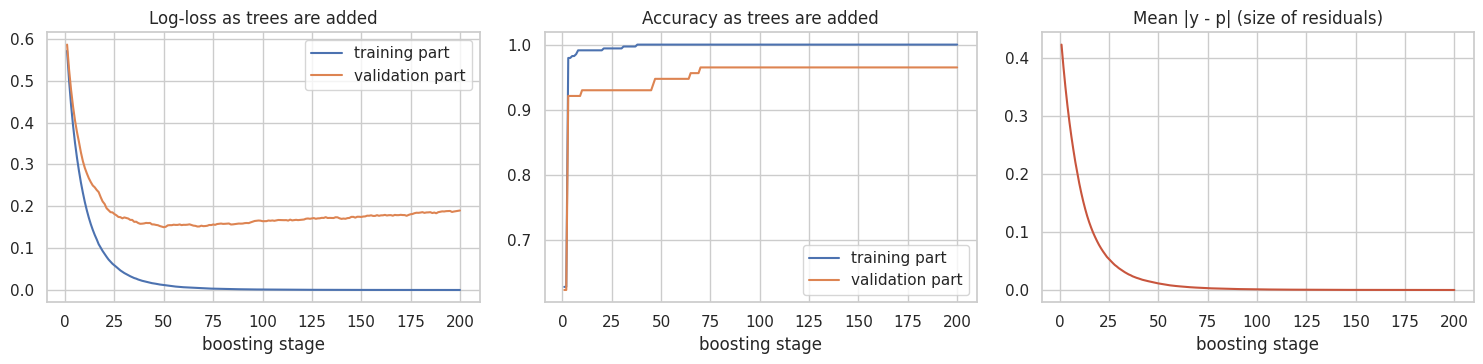

Mean |residual| after stage 1 / 10 / 50 / 200: [0.4236, 0.184, 0.0114, 0.0]
Best validation log-loss at stage 50 (0.1500); at stage 200 it is 0.1899

Gradient Boosting search space: {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]}
Best parameters               : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}
Best CV accuracy              : 0.9736   (AdaBoost tuned: 0.9736)


In [16]:
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=SEED)
gb_cv = cv_eval("Gradient Boosting (100, lr=0.1)", gb)

# Learning process: watch the model improve stage by stage (validation part carved out of the TRAINING set)
X_a, X_v, y_a, y_v = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED)
gb_demo = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=SEED).fit(X_a, y_a)

ll_a = [log_loss(y_a, p) for p in gb_demo.staged_predict_proba(X_a)]
ll_v = [log_loss(y_v, p) for p in gb_demo.staged_predict_proba(X_v)]
ac_a = [accuracy_score(y_a, p) for p in gb_demo.staged_predict(X_a)]
ac_v = [accuracy_score(y_v, p) for p in gb_demo.staged_predict(X_v)]
resid = [np.mean(np.abs(y_a.to_numpy() - p[:, 1])) for p in gb_demo.staged_predict_proba(X_a)]
stages = np.arange(1, 201)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(stages, ll_a, label="training part"); ax[0].plot(stages, ll_v, label="validation part")
ax[0].set_title("Log-loss as trees are added"); ax[0].set_xlabel("boosting stage"); ax[0].legend()
ax[1].plot(stages, ac_a, label="training part"); ax[1].plot(stages, ac_v, label="validation part")
ax[1].set_title("Accuracy as trees are added"); ax[1].set_xlabel("boosting stage"); ax[1].legend()
ax[2].plot(stages, resid, color="#C8553D"); ax[2].set_title("Mean |y - p| (size of residuals)"); ax[2].set_xlabel("boosting stage")
plt.tight_layout(); savefig("q14_gb_stages"); plt.show()
print("Mean |residual| after stage 1 / 10 / 50 / 200:", [round(float(resid[i - 1]), 4) for i in (1, 10, 50, 200)])
print(f"Best validation log-loss at stage {int(np.argmin(ll_v)) + 1} ({min(ll_v):.4f}); at stage 200 it is {ll_v[-1]:.4f}")

# small CV grid on the training data -> final Gradient Boosting configuration
gb_grid = {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]}
gb_search = GridSearchCV(GradientBoostingClassifier(random_state=SEED), gb_grid, cv=CV,
                         scoring="accuracy", n_jobs=1).fit(X_train, y_train)
print("\nGradient Boosting search space:", gb_grid)
print("Best parameters               :", gb_search.best_params_)
print(f"Best CV accuracy              : {gb_search.best_score_:.4f}   (AdaBoost tuned: {ada_search.best_score_:.4f})")

**Learning process.** Use the plotted training and validation curves to observe how loss, accuracy and residual size change as trees are added. A widening gap between training and validation performance can indicate overfitting.

**Compared with AdaBoost:** AdaBoost increases the weights of incorrectly classified observations, while Gradient Boosting fits new trees to the residuals (negative gradients) of a selected loss function. Gradient Boosting therefore provides a general loss-based framework.

## Q15. XGBoost

**XGBoost = eXtreme Gradient Boosting.** It is an optimised gradient-boosting library that adds a regularised objective (L1/L2 penalties on leaf weights and a penalty per leaf), uses a second-order (gradient + Hessian) approximation of the loss, shrinkage, row/column subsampling, built-in handling of missing values and parallel tree building.

To investigate `learning_rate`, `n_estimators` and `max_depth` together, the next cell cross-validates **every combination** (a full grid, 2 × 2 × 2 = 8 settings, 5 folds each, training data only) and then shows the effect of each parameter by averaging over the other two.

Search space: {'learning_rate': [0.05, 0.1], 'n_estimators': [50, 100], 'max_depth': [2, 3]}
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100} | best CV accuracy = 0.9714
Range of CV accuracy over the 36 settings: 0.9538 - 0.9714

learning_rate:
                 mean     min     max
learning_rate                        
0.05           0.9615  0.9538  0.9692
0.10           0.9681  0.9648  0.9714

n_estimators:
                mean     min     max
n_estimators                        
50            0.9604  0.9538  0.9670
100           0.9692  0.9670  0.9714

max_depth:
             mean     min     max
max_depth                        
2          0.9648  0.9538  0.9692
3          0.9648  0.9560  0.9714


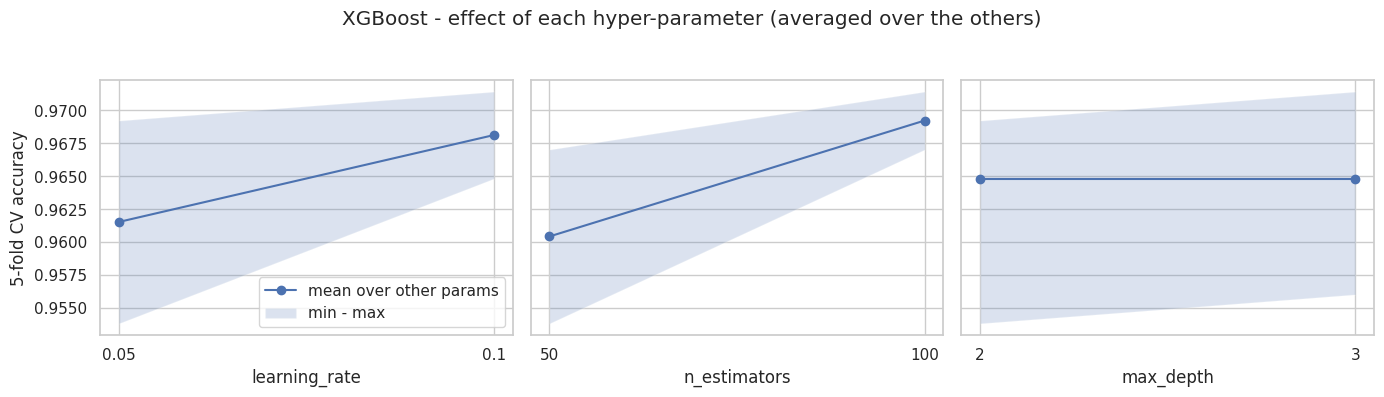

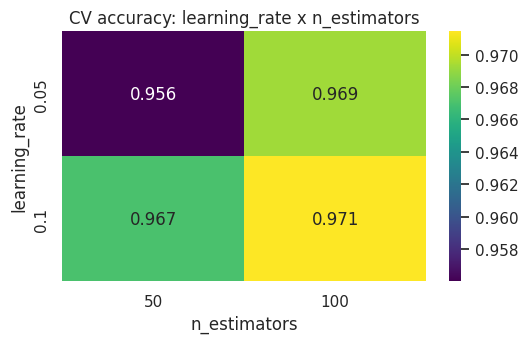

XGBoost (tuned)                  CV accuracy = 0.9714 +/- 0.0112   (0.56s)


In [17]:
xgb_fixed = dict(eval_metric="logloss", random_state=SEED, n_jobs=1, verbosity=0)
xgb_grid = {"learning_rate": [0.05, 0.1],
            "n_estimators":  [50, 100],
            "max_depth":     [2, 3]}
xgb_search = GridSearchCV(XGBClassifier(**xgb_fixed), xgb_grid, cv=CV, scoring="accuracy", n_jobs=1).fit(X_train, y_train)
xr = pd.DataFrame(xgb_search.cv_results_).rename(columns={"param_learning_rate": "learning_rate",
                                                         "param_n_estimators": "n_estimators",
                                                         "param_max_depth": "max_depth"})
for c in ["learning_rate", "n_estimators", "max_depth"]:
    xr[c] = pd.to_numeric(xr[c])

print("Search space:", xgb_grid)
print("Best parameters:", xgb_search.best_params_, f"| best CV accuracy = {xgb_search.best_score_:.4f}")
print(f"Range of CV accuracy over the 36 settings: {xr['mean_test_score'].min():.4f} - {xr['mean_test_score'].max():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, p in zip(axes, ["learning_rate", "n_estimators", "max_depth"]):
    g = xr.groupby(p)["mean_test_score"].agg(["mean", "min", "max"])
    ax.plot(range(len(g)), g["mean"], marker="o", label="mean over other params")
    ax.fill_between(range(len(g)), g["min"], g["max"], alpha=0.2, label="min - max")
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index); ax.set_xlabel(p)
    print(f"\n{p}:"); print(g.round(4))
axes[0].set_ylabel("5-fold CV accuracy"); axes[0].legend()
plt.suptitle("XGBoost - effect of each hyper-parameter (averaged over the others)", y=1.04)
plt.tight_layout(); savefig("q15_xgb_effects"); plt.show()

# learning rate x number of trees (best depth for each cell)
piv = xr.pivot_table(index="learning_rate", columns="n_estimators", values="mean_test_score", aggfunc="max")
plt.figure(figsize=(5.5, 3.6)); sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis")
plt.title("CV accuracy: learning_rate x n_estimators"); plt.tight_layout(); savefig("q15_xgb_heatmap"); plt.show()

xgb_cv = cv_eval("XGBoost (tuned)", clone(xgb_search.best_estimator_))

**How to read the results.** The printed tables and plots show the measured effect of each parameter. `learning_rate` controls the contribution of each tree; `n_estimators` controls the number of boosting stages; and `max_depth` controls tree complexity. Small learning rates may need more trees, while deeper trees can increase overfitting risk. Use the reported cross-validation results to describe the observed trends rather than assuming one setting is always best.

## Q16. LightGBM

**LightGBM = Light Gradient Boosting Machine.** Its main differences from XGBoost: **histogram-based** split finding (features are binned into discrete buckets, which is fast and light on memory), **leaf-wise** (best-first) tree growth instead of level-wise growth, and optional GOSS (gradient-based one-side sampling) and EFB (exclusive feature bundling) for very large data.

**Same evaluation conditions:** same folds (`CV`), same data, `n_estimators=100`, `learning_rate=0.1`, `max_depth=3` (`num_leaves=8 = 2³`), one thread each, timing repeated 3 times and averaged.

In [18]:
xgb_same = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, eval_metric="logloss",
                         random_state=SEED, n_jobs=1, verbosity=0)
lgb_same = LGBMClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, num_leaves=8,
                          random_state=SEED, n_jobs=1, verbose=-1)

def timed_cv(model, name, repeats=3):
    accs, wall, fit = [], [], []
    for _ in range(repeats):
        t0 = time.perf_counter()
        r = cross_validate(model, X_train, y_train, cv=CV, scoring="accuracy")
        wall.append(time.perf_counter() - t0); accs.append(r["test_score"]); fit.append(np.mean(r["fit_time"]))
    a = np.mean(accs, axis=0)
    return {"Model": name, "CV mean accuracy": a.mean(), "CV std": a.std(),
            "CV wall time (s)": np.mean(wall), "Avg fit time per fold (s)": np.mean(fit)}

cmp_xl = pd.DataFrame([timed_cv(xgb_same, "XGBoost"), timed_cv(lgb_same, "LightGBM")])
display(cmp_xl.round(4))
for _, r in cmp_xl.iterrows():
    cv_log.append({"Model": f"{r['Model']} (same conditions)", "CV mean accuracy": r["CV mean accuracy"],
                   "CV std": r["CV std"], "CV time (s)": r["CV wall time (s)"]})

# small CV grid -> final LightGBM configuration (training data only)
lgb_grid = {"learning_rate": [0.05, 0.1], "n_estimators": [100, 200],
            "num_leaves": [4, 8], "min_child_samples": [10]}
lgb_search = GridSearchCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), lgb_grid,
                          cv=CV, scoring="accuracy", n_jobs=1).fit(X_train, y_train)
print("\nLightGBM search space:", lgb_grid)
print("Best parameters      :", lgb_search.best_params_, f"| best CV accuracy = {lgb_search.best_score_:.4f}")

x, l = cmp_xl.iloc[0], cmp_xl.iloc[1]
faster = "LightGBM" if l["Avg fit time per fold (s)"] < x["Avg fit time per fold (s)"] else "XGBoost"
print(f"CV accuracy  XGBoost {x['CV mean accuracy']:.4f} | LightGBM {l['CV mean accuracy']:.4f}\nFit time per fold  XGBoost {x['Avg fit time per fold (s)']*1000:.0f} ms | LightGBM {l['Avg fit time per fold (s)']*1000:.0f} ms")

,Model,CV mean accuracy,CV std,CV wall time (s),Avg fit time per fold (s)
0,XGBoost,0.9714,0.0112,0.5462,0.1028
1,LightGBM,0.9626,0.0204,0.2113,0.0377



LightGBM search space: {'learning_rate': [0.05, 0.1], 'n_estimators': [100, 200], 'num_leaves': [4, 8], 'min_child_samples': [10]}
Best parameters      : {'learning_rate': 0.05, 'min_child_samples': 10, 'n_estimators': 200, 'num_leaves': 4} | best CV accuracy = 0.9692
CV accuracy  XGBoost 0.9714 | LightGBM 0.9626
Fit time per fold  XGBoost 103 ms | LightGBM 38 ms


**Interpretation.** Compare the cross-validation accuracy and measured training time under the same folds and model settings. The timings can vary with hardware and software versions, so report the values produced in your own run. On this relatively small dataset, differences in runtime may be very small.

## Q17. Voting ensembles

* **Hard voting** — each model casts one vote for a class; the majority label wins.
* **Soft voting** — the predicted class probabilities are averaged and the class with the highest average wins. This needs probability outputs, so the SVC is created with `probability=True`.

Members: Logistic Regression (scaled), the **tuned Random Forest** from Q12, and an RBF Support Vector Classifier (scaled).

In [19]:
lr_model  = with_scaler(LogisticRegression(max_iter=2000, random_state=SEED))
svc_model = with_scaler(SVC(kernel="rbf", probability=True, random_state=SEED))      # probability=True for soft voting
rf_model  = RandomForestClassifier(**best_rf_params, random_state=SEED, n_jobs=1)
members   = [("lr", lr_model), ("rf", rf_model), ("svc", svc_model)]

alone = {n: cv_eval(f"{n} (alone)", m) for n, m in
         [("Logistic Regression", lr_model), ("Random Forest tuned", rf_model), ("SVC", svc_model)]}

vote_hard = VotingClassifier(members, voting="hard")
vote_soft = VotingClassifier(members, voting="soft")
vh_cv = cv_eval("Voting (hard)", vote_hard)
vs_cv = cv_eval("Voting (soft)", vote_soft)
print("\nFold scores  hard:", vh_cv.round(3))
print("Fold scores  soft:", vs_cv.round(3))

best_alone = max(alone.items(), key=lambda kv: kv[1].mean())
print(f"Hard voting {vh_cv.mean():.4f} | soft voting {vs_cv.mean():.4f} | best member ({best_alone[0]}) {best_alone[1].mean():.4f}")

Logistic Regression (alone)      CV accuracy = 0.9736 +/- 0.0149   (0.11s)
Random Forest tuned (alone)      CV accuracy = 0.9714 +/- 0.0179   (2.89s)
SVC (alone)                      CV accuracy = 0.9714 +/- 0.0054   (0.12s)
Voting (hard)                    CV accuracy = 0.9780 +/- 0.0000   (2.72s)
Voting (soft)                    CV accuracy = 0.9780 +/- 0.0139   (2.72s)

Fold scores  hard: [0.978 0.978 0.978 0.978 0.978]
Fold scores  soft: [0.956 0.978 1.    0.978 0.978]
Hard voting 0.9780 | soft voting 0.9780 | best member (Logistic Regression) 0.9736


**Hard vs soft.** Hard voting throws away how *confident* each model is: a model that is 51 % sure counts as much as one that is 99 % sure. Soft voting keeps that information, so a confident member can outvote two hesitant ones, and it yields probabilities that are needed for ROC analysis or for moving the decision threshold. The three members are deliberately different (linear, kernel, tree-based), so their errors are only partly shared — the condition under which voting helps. If one member is already almost as good as the ensemble (a scaled Logistic Regression is very strong on this nearly linearly separable data), the possible gain from voting is small.

## Q18. Stacking ensemble

Base learners: Decision Tree, KNN (scaled), SVC (scaled).  Final estimator: Logistic Regression.

**Why out-of-fold (OOF) predictions prevent leakage.** The meta-learner has to learn *how much to trust each base learner on data it has not seen*. If the base learners were asked to predict the very rows they were trained on, their outputs would be unrealistically good (a fully grown tree reproduces its training labels perfectly), and the meta-learner would learn to trust the over-fitted models blindly — information about the target has leaked into the meta-features. `StackingClassifier` avoids this by splitting the training data into K folds: each base learner is fitted on K−1 folds and predicts the held-out fold, so **every training row's meta-feature comes from a model that never saw that row**. The meta-learner is trained on these OOF predictions; afterwards the base learners are re-fitted on all training rows for use at prediction time.

In [20]:
base_learners = [("dt",  DecisionTreeClassifier(random_state=SEED)),
                 ("knn", with_scaler(KNeighborsClassifier(n_neighbors=5))),
                 ("svc", with_scaler(SVC(kernel="rbf", probability=True, random_state=SEED)))]

stack = StackingClassifier(estimators=base_learners,
                           final_estimator=LogisticRegression(max_iter=2000, random_state=SEED),
                           stack_method="predict_proba",
                           cv=StratifiedKFold(5, shuffle=True, random_state=SEED))   # inner CV -> out-of-fold predictions
stack_cv = cv_eval("Stacking (DT+KNN+SVC -> LR)", stack)
print("Fold scores:", stack_cv.round(3))

# Demonstration of the leakage problem, using only the TRAINING data
tree_full = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
p_in  = tree_full.predict_proba(X_train)[:, 1]                                       # tree predicts rows it was trained on
p_oof = cross_val_predict(DecisionTreeClassifier(random_state=SEED), X_train, y_train,
                          cv=CV, method="predict_proba")[:, 1]                       # tree predicts rows it did not see
print(f"\nDecision-tree meta-feature accuracy, in-sample   : {accuracy_score(y_train, p_in > .5):.3f}   <- leaks (looks perfect)")
print(f"Decision-tree meta-feature accuracy, out-of-fold : {accuracy_score(y_train, p_oof > .5):.3f}   <- honest")
print(f"Stacking CV accuracy: {stack_cv.mean():.4f} | soft voting: {vs_cv.mean():.4f}")

Stacking (DT+KNN+SVC -> LR)      CV accuracy = 0.9736 +/- 0.0164   (1.42s)
Fold scores: [0.967 0.989 0.978 0.945 0.989]

Decision-tree meta-feature accuracy, in-sample   : 1.000   <- leaks (looks perfect)
Decision-tree meta-feature accuracy, out-of-fold : 0.923   <- honest
Stacking CV accuracy: 0.9736 | soft voting: 0.9780


**Result.** The printed demonstration shows why OOF is needed: a decision tree "predicts" its own training rows with ~100 % accuracy, but its honest (out-of-fold) accuracy is much lower. A meta-learner trained on the first kind of predictions would over-trust the tree and fail on new data. Stacking costs more than voting because every base learner is fitted several times (once per inner fold plus a final refit), and with only ~455 rows the meta-learner has little to learn beyond what the base learners already agree on.

## Q19. Final model evaluation

**Step 1 — selection with training data only.** The configuration of each model was already chosen by cross-validation (Q10, Q12–Q16). Here every finalised configuration is scored once more with the same 5-fold CV (accuracy, recall, F1). The **model to be reported as "selected"** is chosen from these CV results: highest mean CV accuracy; ties are broken by higher CV recall (a missed malignant tumour is the costly error), then by shorter training time.

**Step 2 — one-time test-set evaluation.** Every finalised model is fitted on the full training set and evaluated on the untouched test set. **Malignant = positive class.** Training time = mean wall-clock time of 3 fits on the training set (single CPU thread; absolute values depend on the machine).

In [21]:
rf_final = RandomForestClassifier(**best_rf_params, random_state=SEED, n_jobs=1)
final_models = {
    "Decision Tree (baseline)":  DecisionTreeClassifier(random_state=SEED),
    "Bagging":                   BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED),
                                                   n_estimators=best_bag_n, random_state=SEED, n_jobs=1),
    "Random Forest (tuned)":     rf_final,
    "AdaBoost (tuned)":          clone(ada_search.best_estimator_),
    "Gradient Boosting (tuned)": clone(gb_search.best_estimator_),
    "XGBoost (tuned)":           clone(xgb_search.best_estimator_),
    "LightGBM (tuned)":          clone(lgb_search.best_estimator_),
    "Voting (hard)":             VotingClassifier([("lr", lr_model), ("rf", clone(rf_final)), ("svc", svc_model)], voting="hard"),
    "Voting (soft)":             VotingClassifier([("lr", lr_model), ("rf", clone(rf_final)), ("svc", svc_model)], voting="soft"),
    "Stacking":                  clone(stack),
}

# ---- Step 1: cross-validation on the TRAINING set (selection) ----
sel_rows = []
for name, m in final_models.items():
    r = cross_validate(m, X_train, y_train, cv=CV, n_jobs=1,
                       scoring={"acc": "accuracy", "rec": "recall", "f1": "f1"})
    sel_rows.append({"Model": name, "CV accuracy": r["test_acc"].mean(), "CV std": r["test_acc"].std(),
                     "CV recall": r["test_rec"].mean(), "CV F1": r["test_f1"].mean()})
cv_table = pd.DataFrame(sel_rows)

# ---- fit on the full training set, timing 3 fits ----
fitted, fit_secs = {}, {}
for name, m in final_models.items():
    ts = []
    for _ in range(3):
        mm = clone(m); t0 = time.perf_counter(); mm.fit(X_train, y_train); ts.append(time.perf_counter() - t0)
    fitted[name], fit_secs[name] = mm, float(np.mean(ts))

# selection uses ONLY training-set information (CV accuracy, CV recall, training time)
cv_table["Train time (s)"] = cv_table["Model"].map(fit_secs)
cv_table["_acc"] = cv_table["CV accuracy"].round(4)
cv_table["_rec"] = cv_table["CV recall"].round(4)
cv_table = cv_table.sort_values(["_acc", "_rec", "Train time (s)"], ascending=[False, False, True]).drop(columns=["_acc", "_rec"]).reset_index(drop=True)
best_name = cv_table.loc[0, "Model"]
print("Cross-validation on the training set (sorted by the selection rule):")
display(cv_table.round(4))
print(">>> Model selected through cross-validation:", best_name)

Cross-validation on the training set (sorted by the selection rule):


,Model,CV accuracy,CV std,CV recall,CV F1,Train time (s)
0,Voting (soft),0.9780,0.0139,0.9647,0.9702,0.6715
1,Voting (hard),0.9780,0.0000,0.9588,0.9702,0.6595
2,Gradient Boosting (tuned),0.9736,0.0088,0.9588,0.9645,1.4065
3,AdaBoost (tuned),0.9736,0.0112,0.9529,0.9643,0.5933
4,Stacking,0.9736,0.0164,0.9412,0.9634,0.3192
5,XGBoost (tuned),0.9714,0.0112,0.9529,0.9614,0.1077
6,Random Forest (tuned),0.9714,0.0179,0.9529,0.9614,0.6084
7,LightGBM (tuned),0.9692,0.0108,0.9471,0.9583,0.0623
8,Bagging,0.9626,0.0226,0.9412,0.9496,1.0343
9,Decision Tree (baseline),0.9231,0.0326,0.8941,0.8962,0.0231


>>> Model selected through cross-validation: Voting (soft)


In [22]:
# ---- Step 2: the untouched test set (used once) ----
rows = []
for name, mm in fitted.items():
    pred = mm.predict(X_test)
    score = mm.predict_proba(X_test)[:, 1] if name != "Voting (hard)" else None       # hard voting has no probabilities
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall":    recall_score(y_test, pred),
                 "F1-score":  f1_score(y_test, pred),
                 "ROC-AUC":   roc_auc_score(y_test, score) if score is not None else np.nan,
                 "Train time (s)": fit_secs[name],
                 "FP": fp, "FN": fn,
                 "Train acc": accuracy_score(y_train, mm.predict(X_train))})
final_table = pd.DataFrame(rows).merge(cv_table[["Model", "CV accuracy"]], on="Model")
final_table = final_table[["Model", "CV accuracy", "Train acc", "Accuracy", "Precision", "Recall",
                           "F1-score", "ROC-AUC", "Train time (s)", "FP", "FN"]]
final_table.to_csv("results/final_comparison.csv", index=False)
cv_table.to_csv("results/cv_selection.csv", index=False)

print("Test-set comparison (positive class = malignant; ROC-AUC not defined for hard voting):")
display(final_table.round(4).style
        .highlight_max(subset=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"], color="#cfe8cf")
        .format({"ROC-AUC": "{:.4f}"}, na_rep="n/a"))

Test-set comparison (positive class = malignant; ROC-AUC not defined for hard voting):


,Model,CV accuracy,Train acc,Accuracy,Precision,Recall,F1-score,ROC-AUC,Train time (s),FP,FN
0,Decision Tree (baseline),0.923100,1.000000,0.929800,0.904800,0.904800,0.904800,0.9246,0.023100,4,4
1,Bagging,0.962600,1.000000,0.973700,1.000000,0.928600,0.963000,0.9911,1.034300,0,3
2,Random Forest (tuned),0.971400,1.000000,0.973700,1.000000,0.928600,0.963000,0.9904,0.608400,0,3
3,AdaBoost (tuned),0.973600,1.000000,0.964900,0.975000,0.928600,0.951200,0.9881,0.593300,1,3
4,Gradient Boosting (tuned),0.973600,1.000000,0.964900,1.000000,0.904800,0.950000,0.9934,1.406500,0,4
5,XGBoost (tuned),0.971400,1.000000,0.964900,1.000000,0.904800,0.950000,0.9944,0.107700,0,4
6,LightGBM (tuned),0.969200,1.000000,0.973700,1.000000,0.928600,0.963000,0.9974,0.062300,0,3
7,Voting (hard),0.978000,0.989000,0.982500,1.000000,0.952400,0.975600,n/a,0.659500,0,2
8,Voting (soft),0.978000,0.991200,0.982500,1.000000,0.952400,0.975600,0.9960,0.671500,0,2
9,Stacking,0.973600,0.991200,0.964900,0.975000,0.928600,0.951200,0.9967,0.319200,1,3


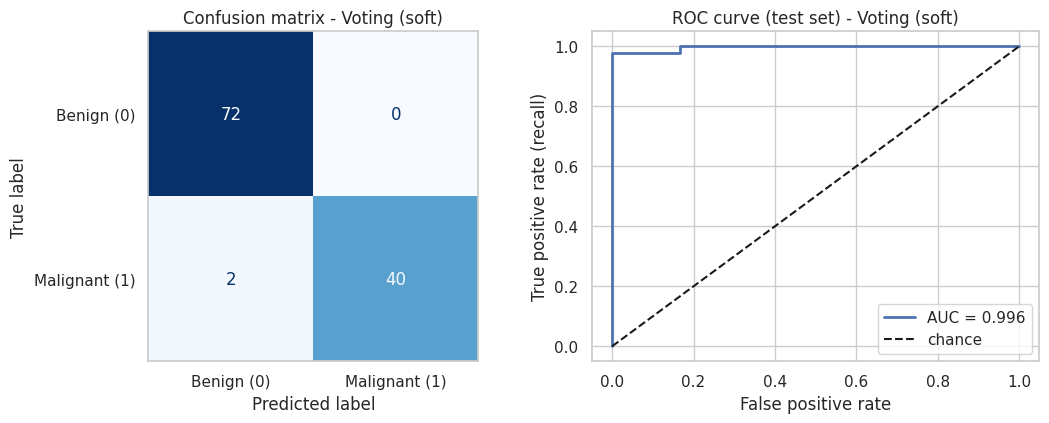

TN = 72   FP = 0   FN = 2   TP = 40


In [23]:
# Confusion matrix + ROC curve of the model chosen through cross-validation
chosen = fitted[best_name]
pred = chosen.predict(X_test)
prob = chosen.predict_proba(X_test)[:, 1] if best_name != "Voting (hard)" else None

fig, ax = plt.subplots(1, 2 if prob is not None else 1, figsize=(11 if prob is not None else 5.5, 4.4))
ax = np.atleast_1d(ax)
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Benign (0)", "Malignant (1)"],
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title(f"Confusion matrix - {best_name}"); ax[0].grid(False)
if prob is not None:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, prob):.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", label="chance")
    ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate (recall)")
    ax[1].set_title(f"ROC curve (test set) - {best_name}"); ax[1].legend(loc="lower right")
plt.tight_layout(); savefig("q19_confusion_roc"); plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"TN = {tn}   FP = {fp}   FN = {fn}   TP = {tp}")

In [24]:
# Data-driven summary of Q19 (numbers come from the tables above)
ft = final_table.set_index("Model")
base_row = ft.loc["Decision Tree (baseline)"]
ens = ft.drop(index="Decision Tree (baseline)")
print(f"Selected through CV: {best_name} | CV accuracy {cv_table.loc[0,'CV accuracy']:.4f} | CV recall {cv_table.loc[0,'CV recall']:.4f}")
print(f"Test set ({best_name}): " + ", ".join(f"{m} {ft.loc[best_name, m]:.4f}" for m in ["Accuracy","Precision","Recall","F1-score","ROC-AUC"] if not np.isnan(ft.loc[best_name, m])) + f", FP {int(ft.loc[best_name,'FP'])}, FN {int(ft.loc[best_name,'FN'])}")
print(f"Baseline tree on test set: accuracy {base_row['Accuracy']:.4f}, recall {base_row['Recall']:.4f} | ensembles with higher accuracy: {(ens['Accuracy'] > base_row['Accuracy']).sum()} of {len(ens)}")
print(f"Best test accuracy: {ens['Accuracy'].idxmax()} ({ens['Accuracy'].max():.4f}) | fastest: {ft['Train time (s)'].idxmin()} | slowest: {ft['Train time (s)'].idxmax()}")
n_test, n_pos = len(y_test), int(y_test.sum())
print(f"Test set size: {n_test} cases ({n_pos} malignant) -> 1 case = {100/n_test:.2f} accuracy points, 1 malignant case = {100/n_pos:.1f} recall points")

Selected through CV: Voting (soft) | CV accuracy 0.9780 | CV recall 0.9647
Test set (Voting (soft)): Accuracy 0.9825, Precision 1.0000, Recall 0.9524, F1-score 0.9756, ROC-AUC 0.9960, FP 0, FN 2
Baseline tree on test set: accuracy 0.9298, recall 0.9048 | ensembles with higher accuracy: 9 of 9
Best test accuracy: Voting (hard) (0.9825) | fastest: Decision Tree (baseline) | slowest: Gradient Boosting (tuned)
Test set size: 114 cases (42 malignant) -> 1 case = 0.88 accuracy points, 1 malignant case = 2.4 recall points


## Q20. Interpretation and conclusion

,importance
perimeter_worst,0.1922
area_worst,0.1747
radius_worst,0.1627
concave points_worst,0.1412
concave points_mean,0.1200
texture_mean,0.0234
texture_worst,0.0215
radius_mean,0.0173
area_se,0.0155
area_mean,0.0153


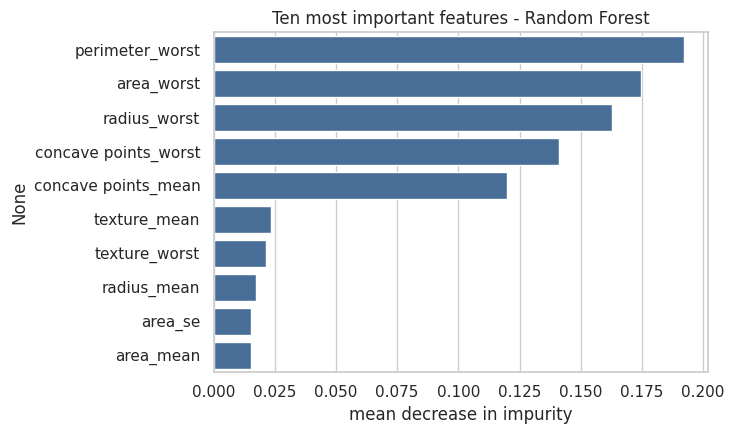

Top 5 share of total importance : 0.791
Top 10 share of total importance: 0.884


In [25]:
# (a) ten most important features according to the (tuned) Random Forest
rf_fit = fitted["Random Forest (tuned)"]
importance = pd.Series(rf_fit.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top10 = importance.head(10)
display(top10.round(4).to_frame("importance"))

plt.figure(figsize=(7.5, 4.5))
sns.barplot(x=top10.values, y=top10.index, color="#3B6EA5")
plt.xlabel("mean decrease in impurity"); plt.title("Ten most important features - Random Forest")
plt.tight_layout(); savefig("q20_feature_importance"); plt.show()
print(f"Top 5 share of total importance : {top10.head(5).sum():.3f}")
print(f"Top 10 share of total importance: {top10.sum():.3f}")

In [26]:
# (b) false positives / false negatives per model (test set)
err_tbl = final_table[["Model", "FP", "FN", "Precision", "Recall"]].sort_values(["FN", "FP"])
display(err_tbl.round(4))

# (c) overfitting check: training vs cross-validation vs test accuracy
gap_tbl = final_table[["Model", "Train acc", "CV accuracy", "Accuracy"]].rename(columns={"Accuracy": "Test acc"})
gap_tbl["Train - CV"] = gap_tbl["Train acc"] - gap_tbl["CV accuracy"]
gap_tbl["CV - Test"]  = gap_tbl["CV accuracy"] - gap_tbl["Test acc"]
display(gap_tbl.sort_values("Train - CV", ascending=False).round(4))

,Model,FP,FN,Precision,Recall
7,Voting (hard),0,2,1.0000,0.9524
8,Voting (soft),0,2,1.0000,0.9524
1,Bagging,0,3,1.0000,0.9286
2,Random Forest (tuned),0,3,1.0000,0.9286
6,LightGBM (tuned),0,3,1.0000,0.9286
3,AdaBoost (tuned),1,3,0.9750,0.9286
9,Stacking,1,3,0.9750,0.9286
4,Gradient Boosting (tuned),0,4,1.0000,0.9048
5,XGBoost (tuned),0,4,1.0000,0.9048
0,Decision Tree (baseline),4,4,0.9048,0.9048


,Model,Train acc,CV accuracy,Test acc,Train - CV,CV - Test
0,Decision Tree (baseline),1.0000,0.9231,0.9298,0.0769,-0.0067
1,Bagging,1.0000,0.9626,0.9737,0.0374,-0.0110
6,LightGBM (tuned),1.0000,0.9692,0.9737,0.0308,-0.0045
2,Random Forest (tuned),1.0000,0.9714,0.9737,0.0286,-0.0023
5,XGBoost (tuned),1.0000,0.9714,0.9649,0.0286,0.0065
3,AdaBoost (tuned),1.0000,0.9736,0.9649,0.0264,0.0087
4,Gradient Boosting (tuned),1.0000,0.9736,0.9649,0.0264,0.0087
9,Stacking,0.9912,0.9736,0.9649,0.0176,0.0087
8,Voting (soft),0.9912,0.9780,0.9825,0.0132,-0.0044
7,Voting (hard),0.9890,0.9780,0.9825,0.0110,-0.0044


In [27]:
# (d) data-driven discussion text
ft = final_table.set_index("Model")
perfect = gap_tbl[gap_tbl["Train acc"] >= 0.999]["Model"].tolist()
worst_gap = gap_tbl.sort_values("Train - CV", ascending=False).iloc[0]
voting_stack = gap_tbl[gap_tbl["Model"].isin(["Voting (hard)", "Voting (soft)", "Stacking"])]
print("TOP FEATURES")
print("Top-5 features:", ", ".join(top10.index[:5]), f"| share of importance {top10.head(5).sum():.1%}")
print("\nFALSE POSITIVES vs FALSE NEGATIVES")
ens = ft.drop(index="Decision Tree (baseline)")
print(f"Ensembles: FP {int(ens['FP'].min())}-{int(ens['FP'].max())}, FN {int(ens['FN'].min())}-{int(ens['FN'].max())} | baseline tree: FP {int(ft.loc['Decision Tree (baseline)','FP'])}, FN {int(ft.loc['Decision Tree (baseline)','FN'])} | selected ({best_name}): FP {int(ft.loc[best_name,'FP'])}, FN {int(ft.loc[best_name,'FN'])}")
print("\nOVERFITTING")
print(f"Models with ~100% training accuracy: {len(perfect)} of {len(gap_tbl)} | largest train-CV gap: {worst_gap['Model']} ({worst_gap['Train - CV']*100:.1f} pts) | voting/stacking gaps: {voting_stack['Train - CV'].min()*100:.1f}-{voting_stack['Train - CV'].max()*100:.1f} pts | mean |CV-test|: {gap_tbl['CV - Test'].abs().mean()*100:.1f} pts")
print("\nPREFERRED ENSEMBLE")
non_base = ens.copy()
print(f"Preferred model: {best_name} | CV acc {cv_table.loc[0,'CV accuracy']:.4f} | test acc {ft.loc[best_name,'Accuracy']:.4f} | recall {ft.loc[best_name,'Recall']:.4f} | F1 {ft.loc[best_name,'F1-score']:.4f} | train time {ft.loc[best_name,'Train time (s)']:.3f}s | train-CV gap {gap_tbl.set_index('Model').loc[best_name,'Train - CV']*100:.1f} pts")

TOP FEATURES
Top-5 features: perimeter_worst, area_worst, radius_worst, concave points_worst, concave points_mean | share of importance 79.1%

FALSE POSITIVES vs FALSE NEGATIVES
Ensembles: FP 0-1, FN 2-4 | baseline tree: FP 4, FN 4 | selected (Voting (soft)): FP 0, FN 2

OVERFITTING
Models with ~100% training accuracy: 7 of 10 | largest train-CV gap: Decision Tree (baseline) (7.7 pts) | voting/stacking gaps: 1.1-1.8 pts | mean |CV-test|: 0.7 pts

PREFERRED ENSEMBLE
Preferred model: Voting (soft) | CV acc 0.9780 | test acc 0.9825 | recall 0.9524 | F1 0.9756 | train time 0.672s | train-CV gap 1.3 pts


### Written discussion

**False positives vs false negatives.** A *false positive* (FP) means a benign tumour is called malignant: the patient faces extra tests or a biopsy, anxiety and cost, but the error is normally caught later. A *false negative* (FN) means a malignant tumour is called benign: a missed or delayed diagnosis, which is the **more dangerous** error. Because the positive class is malignant, **recall** measures how few cancers are missed and **precision** how few false alarms are raised. Models tuned for plain accuracy lean towards the majority (benign) class; if missed cancers are considered costlier, the probability threshold could be lowered (chosen with cross-validated *training* predictions, never the test set) or a recall-oriented metric could be used for tuning.

**Signs of overfitting.** Deep trees, bagging, forests and boosted models can reach 100 % training accuracy while scoring lower in cross-validation. A perfect training score is not harmful by itself; the warning sign is the **train − CV gap** (largest for the single tree). The Decision Tree overfits strongly (high variance), the tree ensembles only mildly, and voting/stacking, which mix in smooth models such as Logistic Regression and SVC, typically show smaller gaps (check the table above). If CV and test accuracy agree closely, the selection procedure has not overfitted the validation folds. Further reduction would come from shallower trees, subsampling, stronger regularisation or early stopping.

**Justification of the preferred ensemble.** The preferred model is the one chosen by the cross-validation rule in Q19 (see the tables above for its exact numbers). Reasons: (1) it was selected **without looking at the test set**; (2) it combines models of different types, so their errors partly cancel; (3) its generalisation gap is small; (4) it trains in a fraction of a second and gives probabilities. Boosted models (XGBoost / LightGBM / Gradient Boosting) are close competitors and are the better choice when data are large, while a tuned Random Forest is preferred when interpretability through feature importance is needed.

**Limitations (honest reporting).** The test set is small (114 cases), so differences of one or two cases between the leading models are within random variation; one strong linear model (scaled Logistic Regression) is already close to the ensembles because this dataset is almost linearly separable, so the benefit of ensembling over a strong single model is modest; and all results come from one stratified split. What the experiments show clearly is that the ensembles consistently outperform the single, unpruned decision tree, mainly by reducing variance.

## References
1. Wolberg, W. H., Street, W. N., Mangasarian, O. L. (1995). *Breast Cancer Wisconsin (Diagnostic) Data Set.* UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B  
2. Kaggle: *Breast Cancer Wisconsin (Diagnostic) Data Set.* https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data  
3. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825–2830.  
4. Chen, T., Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*, 785–794.  
5. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 30*.  
6. Breiman, L. (1996). Bagging Predictors. *Machine Learning* 24, 123–140. Breiman, L. (2001). Random Forests. *Machine Learning* 45, 5–32.  
7. Freund, Y., Schapire, R. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *JCSS* 55(1), 119–139.  
8. Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics* 29(5), 1189–1232.  
9. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks* 5(2), 241–259.  
10. Harris et al. (2020) NumPy; McKinney (2010) pandas; Hunter (2007) Matplotlib; Waskom (2021) seaborn.